<a href="https://colab.research.google.com/github/dsumathiphd/TYL-Agentic-AI/blob/main/AI_Agent_Lang_Grpaph.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
pip install langgraph[all]

In [ ]:
pip install typing

In [ ]:
from typing import Dict, TypedDict
from langgraph.graph import StateGraph


In [ ]:
class AgentState(TypedDict):
    message: str


In [ ]:
def greeting_node(state: AgentState) -> AgentState:
    """Simple Node that adds greeting message to the state"""

    state["message"]="Hey " + state["message"] + ", how are you? "
    return state

In [ ]:
graph = StateGraph(AgentState)

graph.add_node("greeter", greeting_node)
graph.set_entry_point("greeter")
graph.set_finish_point("greeter")

app = graph.compile()



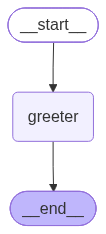

In [ ]:
from IPython.display import Image, display
display(Image(app.get_graph().draw_mermaid_png()))


In [ ]:
result = app.invoke({"message":"Sumathi"})

In [ ]:
result

{'message': 'Hey  Sumathi, how are you? '}

Example 2 - This agent Handles multiple inputs

Received State: {'name10': 'Sumathi', 'values': [10, 20, 30], 'result': ''}
Hi there Sumathi! Your sum = 60


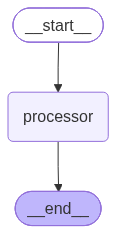

In [ ]:
#result=app1.invoke({'name10':'Sumathi','values':[10,20,30]})

from typing import TypedDict
from langgraph.graph import StateGraph

class AgentState1(TypedDict):
    name10: str
    values: list[int]
    result: str

def process_values(state: AgentState1) -> AgentState1:
    print("Received State:", state)

    state["result"] = f"Hi there {state['name10']}! Your sum = {sum(state['values'])}"

    return state

g = StateGraph(AgentState1)

g.add_node("processor", process_values)

g.set_entry_point("processor")
g.set_finish_point("processor")

app1 = g.compile()

result = app1.invoke({
    "name10": "Sumathi",
    "values": [10, 20, 30],
    "result": ""
})

print(result["result"])
Image(app1.get_graph().draw_mermaid_png())
  # display(Image)

Exampel 3

In [ ]:
from typing import TypedDict
from langgraph.graph import StateGraph

class StudentState(TypedDict):
  name: str
  age: int
  sub1: int
  sub2: int
  sub2: int
  tot: int
  final: str




In [ ]:
# Node - 1 : introduce  student
def student_intro(state: StudentState) -> StudentState:
   state["final"] = f"hi, my name is {state['name']} and I am {state['age']} years old"
   return state

def calculate_total(state: StudentState) -> StudentState:
   tot_marks = state["sub1"] + state["sub2"]
   state["tot"] = tot_marks
   state["final"] += f"I Scored {tot_marks} marks in total."
   return state

def final_summary(state: StudentState) -> StudentState:
  state["final"] += f"({state['sub1']}, {state['sub2']}) and totel marks {state['tot']}"
  return state


In [ ]:
# Build the graph
graph = StateGraph(StudentState)

graph.add_node("student_intro", student_intro)
graph.add_node("calculate_total", calculate_total)
graph.add_node("final_summary", final_summary)

graph.set_entry_point("student_intro")
graph.add_edge("student_intro", "calculate_total")
graph.add_edge("calculate_total", "final_summary")
graph.set_finish_point("final_summary")

app = graph.compile()


Example 4

In [ ]:
from typing import TypedDict
from langgraph.graph import StateGraph, START, END

# Define State
class AgentState1(TypedDict):
    name10: str
    values: list[int]
    operation: str
    result: str


# Router Node
def router(state: AgentState1) -> AgentState1:
    print("Router checking operation:", state["operation"])
    return state


# Conditional Routing Function
def choose_operation(state: AgentState1) -> str:
    if state["operation"] == "+":
        return "addition"
    elif state["operation"] == "-":
        return "subtraction"
    else:
        return "invalid"


# Addition Node
def addition(state: AgentState1) -> AgentState1:
    total = sum(state["values"])
    state["result"] = f"Hi {state['name10']}! Addition result = {total}"
    return state


# Subtraction Node
def subtraction(state: AgentState1) -> AgentState1:
    print("Subtraction node executed!")

    values = state["values"]
    difference = values[0] - values[1]

    state["result"] = f"Hi {state['name10']}! Subtraction result = {difference}"
    return state


# Invalid Operation Node
def invalid_operation(state: AgentState1) -> AgentState1:
    state["result"] = "Invalid operation! Please select + or -."
    return state


# Create Graph
g = StateGraph(AgentState1)

# Add Nodes
g.add_node("router", router)
g.add_node("addition", addition)
g.add_node("subtraction", subtraction)
g.add_node("invalid", invalid_operation)

# Entry Point
g.add_edge(START, "router")

# Conditional Edge
g.add_conditional_edges(
    "router",
    choose_operation,
    {
        "addition": "addition",
        "subtraction": "subtraction",
        "invalid": "invalid"
    }
)

# End Points
g.add_edge("addition", END)
g.add_edge("subtraction", END)
g.add_edge("invalid", END)

# Compile
app2 = g.compile()

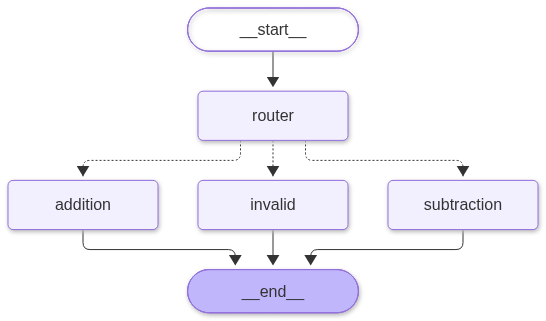

In [ ]:
# Visualizing Graph
from IPython.display import Image, display

display(Image(app2.get_graph().draw_mermaid_png()))


In [ ]:
# Test Condition "+"
result = app2.invoke({
    "name10": "Sumathi",
    "values": [10, 20],
    "operation": "+",
    "result": ""
})

print(result["result"])


Router checking operation: +
Hi Sumathi! Addition result = 30


In [ ]:
# Test Condition "-"
result = app2.invoke({
    "name10": "Sumathi",
    "values": [40, 20],
    "operation": "-",
    "result": ""
})

print(result)
print(result["result"])

Router checking operation: -
Subtraction node executed!
{'name10': 'Sumathi', 'values': [40, 20], 'operation': '-', 'result': 'Hi Sumathi! Subtraction result = 20'}
Hi Sumathi! Subtraction result = 20


In [ ]:
# Invalid Operation

result = app2.invoke({
    "name10": "Sumathi",
    "values": [50, 20],
    "operation": "*",
    "result": ""
})

print(result["result"])

Router checking operation: *
Invalid operation! Please select + or -.
